# Binarizarea imaginilor prin compararea cu un prag: metoda Otsu

Laboratorul 5, DEPI

# 1. Obiectiv

Citirea și afișarea imaginilor în tonuri de gri în Matlab, interpretarea
histogramelor acestora și implementarea binarizării imaginilor prin
căutarea pragului cu metoda Otsu, pe baza varianțelor din interiorul
grupurilor.

# 2. Aspecte teoretice

## 2.1 O imagine în tonuri de gri este o matrice

O imagine digitală este o matrice dreptunghiulară de **pixeli**.

O imagine în tonuri de gri (*grayscale*) are câte o valoare pentru
fiecare pixel, valorile fiind aranjate într-o matrice `I`.

Valorile pixelilor sunt numere între 0 și 1 (de tip `double`) sau între
0 și 255 (de tip `uint8`).

- 0 reprezintă negru;
- valoarea maximă (1 sau 255) reprezintă alb;
- valorile intermediare reprezintă nuanțe de gri.

În acest laborator, preferăm valori ale pixelilor în intervalul 0–1, de
tip `double`, care permite calcule precise.

De exemplu, următoarele comenzi creează și afișează o imagine mică în
tonuri de gri:

``` matlab
I_small = [0 0.25 0.5 1; 0 0.25 0.5 1; 0 0.25 0.5 1]; % O matrice de 3 pe 4 cu valori între 0 și 1
imshow(I_small)
```

Imaginile pot fi citite dintr-un fișier cu funcția `imread()`, ca în
exemplul de mai jos:

``` matlab
I = imread('coins.png');
% I = rgb2gray(I);  % Dacă imaginea este RGB, se convertește la grayscale
I = im2double(I);
imshow(I)
```

Funcții folosite:

- `imread()` citește o imagine dintr-un fișier și returnează matricea
  pixelilor;
- `rgb2gray()` convertește o imagine RGB în grayscale, dacă este
  necesar;
- `im2double()` convertește matricea imaginii la tipul `double` și îi
  rescalează valorile în intervalul 0–1.
- `imshow()` afișează matricea ca imagine.

Imaginile folosite în acest laborator sunt deja în tonuri de gri, deci
nu trebuie convertite din RGB în *grayscale*.

## 2.2 Histograma imaginii

Histograma imaginii numără câți pixeli au fiecare valoare, și arată
distribuția valoriloe.

Folosiți `imhist()` pentru a afișa histograma imaginii:

``` matlab
figure
imhist(I)
xlabel('Intensitate')
ylabel('Număr de pixeli')
```

Pentru o imagine în tonuri de gri, `imhist(I)` folosește implicit 256 de
intervale. Folosiți `imhist(I,64)` pentru a specifica un alt număr de
intervale (aici 64).

Pentru a transforma o matrice într-un vector, concatenând toate
coloanele, folosiți `I(:)`. Acest lucru este util pentru calculele care
nu depind de pozițiile pixelilor:

``` matlab
pixels = I(:);
```

<figure>
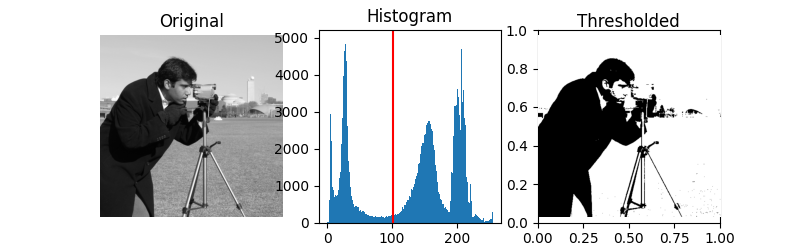
<figcaption aria-hidden="true">O fotografie reală în tonuri de gri,
histograma sa și binarizarea sa. Linia roșie marchează pragul Otsu în
acest exemplu.</figcaption>
</figure>

## 2.3 Compararea cu un prag și binarizarea imaginilor

**Binarizarea unei imagini** transformă o imagine în tonuri de gri
într-o imagine binară, cu doar două valori (0=negru și 1=alb).

Putem face acest lucru prin **compararea cu un prag**, adică prin
compararea cu o valoare de prag $T$:

- toți pixelii $\leq T$ devin 0
- toți pixelii $> T$ devin 1

``` matlab
BW = I > 0.5;
figure
imshow(BW)
```

`BW` are același număr de linii și de coloane ca `I`. Valorile sale sunt
`false` (= 0, afișat ca negru) și `true` (=1, afișat ca alb).

## 2.4 Întrebare: cum alegem pragul $T$?

Problema este alegerea unui **prag bun**, care să separe partea mai
întunecată a imaginii de partea mai luminoasă, nu prin apreciere
vizuală, ci pe baza unui criteriu automat.

## 2.5 Criteriul Otsu: grupurile trebuie să fie compacte

Metoda Otsu alege un prag care minimizează **varianța ponderată a
grupurilor**.

- pentru i = \[1:254\]:
  - calculați pragul $T = i/255$ (astfel încât să aibă valori în
    intervalul 0–1)
  - împărțiți pixelii în două grupuri:
    - $C_0$ = pixelii $\leq T$
    - $C_1$ = pixelii $> T$
  - calculați numărul de pixeli din fiecare grup, $N_0$ și $N_1$
  - calculați **media** și **varianța** fiecărui grup, $m_0$, $m_1$,
    $v_0$, $v_1$
  - calculați **suma ponderată a varianțelor**:
    $$ J = \frac{N_0}{N_0+N_1} v_0 + \frac{N_1}{N_0+N_1} v_1 $$
  - salvați scorul $J$ pentru acest prag $i$ într-un vector `scores(i)`
- Alegeți pragul care a produs **scorul minim** din `scores`.

În Matlab, pentru a calcula media și varianța unui vector `x`, folosiți:

``` matlab
m = mean(x);
v = var(x,1);  % Folosiți aici normalizarea cu N
```

Dacă unul dintre cele două grupuri este gol, nu se poate calcula media
sau varianța. Omiteți acel prag și setați scorul său $J$ la `Inf`
(infinit).

## 2.6 Rezumat: funcții și notații de cunoscut

| Sintaxă sau notație | Exemplu | Descriere |
|------------------------|------------------------|------------------------|
| `imread(filename)` | `I = imread('coins.png')` | Citește o imagine și returnează matricea pixelilor |
| `rgb2gray(I)` | `I = rgb2gray(I)` | Convertește o imagine RGB în tonuri de gri |
| `im2double(I)` | `I = im2double(I)` | Convertește o imagine la tipul `double`, rescalând valorile din 0–255 în 0–1 |
| `imshow(I)` | `imshow(I)` | Afișează o imagine I |
| `size(I)`, `numel(I)` | `size(I)`, `numel(I)` | Dimensiunile imaginii și numărul total de pixeli |
| `I(:)` | `pixels = I(:)` | Transformă o matrice într-un vector coloană |
| `imhist(I)`, `imhist(I,n)` | `imhist(I,64)` | Afișează histograma imaginii; implicit sunt 256 de intervale pentru imagini în tonuri de gri |
| `I > T` | `BW = I > 0.5` | Binarizare: pixelii deasupra pragului devin 1, ceilalți 0 |
| Indexare logică | `C0 = pixels(pixels <= T)` | Extrage valorile care îndeplinesc o condiție |
| `numel(x)` | `N0 = numel(C0)` | Numără pixelii dintr-un vector |
| `mean(x)` | `m0 = mean(C0)` | Intensitatea medie a unui vector |
| `var(x,1)` | `v0 = var(C0,1)` | Varianța, normalizată cu numărul de pixeli |
| `Inf(m,n)` | `scores = Inf(1,254)` | Inițializează scorurile cu infinit, astfel încât pragurile omise să nu poată fi selectate |
| `min(x)` | `[minScore,index] = min(scores)` | Valoarea minimă dintr-un vector și poziția sa (prima sa apariție) |

# 3. Exerciții

Scrieți comenzile într-un script sau live script, cu excepția funcției
din Exercițiul 2, care se scrie într-un fișier separat.

1.  Citiți, afișați și binarizați o imagine:

    1.  Citiți imaginea `coins.png` în variabila `I`, convertiți
        imaginea la tipul `double` și la intervalul 0–1 și afișați-o.

    2.  Afișați histograma imaginii. Care valori corespund fundalului și
        care monedelor?

    3.  Alegeți un prag $T$ examinând imaginea și histograma sa. Creați
        imaginea binară `BW` prin compararea cu pragul $T$ și afișați
        `BW`.

    4.  Afișați histograma lui `BW`. Care sunt cele două valori ale
        intensității care rămân?

2.  Implementați metoda Otsu ca funcție:

    1.  Creați fișierul `otsuManual.m` cu următorul antet:

        ``` matlab
        function [bestThreshold] = otsuManual(I)
        ```

        Argumentul de intrare `I` este o imagine în tonuri de gri, de
        tip `double`, în intervalul 0–1. Returnați cel mai bun prag
        găsit cu algoritmul descris mai sus.

3.  Aplicați funcția:

    1.  Apelați funcția pentru imaginea normalizată `I` din Exercițiul
        1:

        ``` matlab
        bestThreshold = otsuManual(I);
        ```

        Care este valoarea lui `bestThreshold`?

    2.  Binarizați imaginea `I` cu `bestThreshold` și afișați
        rezultatul.

4.  Repetați Exercițiul 3 pentru imaginea `Lab5_handwrittenText.png`.